# 05. Previous art и интерпретация

Эксперименты 7–9:

7. **IACIS 2022:** R² по оценке на подвыборке 12 стран × 26 сортов × 12 дегустаторов, у авторов R² = 0.593.
8. **Journal of Wine Economics 2022:** классификация оценки на 2 класса (80–89 / 90+) и 4 класса (80–84 / 85–89 / 90–94 / 95–100),
   у BERT из статьи accuracy 89% и 82%.
9. **SHAP и анализ ошибок:** какие слова и поля метаданных двигают прогноз RoBERTa и на каких винах модель ошибается.

Новые модели здесь не обучаются: используются предсказания на test и чекпойнты RoBERTa, сохранённые в ноутбуках 02–04.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from src.config import POINTS_COL, LOG_PRICE_COL
from src.split import load_splits, iacis_test_mask
from src.data import points_to_class, score_to_class
from src.metrics import regression_metrics, classification_metrics, log_metrics, load_predictions
from src.plots import set_style, save, MAIN, PALETTE, TEXT_MUTED

set_style()
_, _, test = load_splits()

EXPS = ["mean", "meta_catboost", "tfidf_ridge", "emb_catboost", "emb_meta_catboost", "roberta_text", "roberta_meta"]
NAMES = {
    "mean": "среднее",
    "meta_catboost": "метаданные + CatBoost",
    "tfidf_ridge": "TF-IDF + Ridge",
    "emb_catboost": "эмбеддинги + CatBoost",
    "emb_meta_catboost": "эмбеддинги + мета + CatBoost",
    "roberta_text": "RoBERTa, текст",
    "roberta_meta": "RoBERTa, текст + мета",
}
USES_TEXT = {"tfidf_ridge", "emb_catboost", "emb_meta_catboost", "roberta_text", "roberta_meta"}

## 1. Сравнение с IACIS 2022

Подвыборка построена в ноутбуке 00: самые частые 12 стран, 26 сортов и 12 дегустаторов, только вина с ценой.
Точных списков из статьи нет, поэтому это приближение их условий. Строки подвыборки остаются в той же части разбиения,
что и в основном сплите, поэтому её test не пересекается с train ни одной модели.

Модели обучены на полном train, а не только на подвыборке: так у них больше данных, чем было у авторов.
Это нужно помнить при сравнении, хотя подвыборка составляет 60% данных и в ней самые массовые категории.

In [2]:
mask = iacis_test_mask(test)
print(f"test подвыборки IACIS: {mask.sum():,} из {len(test):,} отзывов")

rows = {}
for e in EXPS:
    for t in (POINTS_COL, LOG_PRICE_COL):
        p = load_predictions(e, t)[mask.values]
        m = regression_metrics(p["y_true"], p["y_pred"])
        log_metrics(e, f"{t}_iacis", m)
        rows[(NAMES[e], t)] = m
iacis = pd.DataFrame(rows).T.unstack(1).swaplevel(0, 1, axis=1).sort_index(axis=1)
iacis = iacis.loc[[NAMES[e] for e in EXPS],
                  [(POINTS_COL, "RMSE"), (POINTS_COL, "R2"), (LOG_PRICE_COL, "MAE"), (LOG_PRICE_COL, "R2")]]
iacis.round(3)

test подвыборки IACIS: 6,612 из 11,157 отзывов


points        log_price       
                               RMSE     R2       MAE     R2
среднее                       3.066 -0.011     0.543 -0.002
метаданные + CatBoost         2.137  0.509     0.281  0.679
TF-IDF + Ridge                1.664  0.702     0.373  0.484
эмбеддинги + CatBoost         1.891  0.615     0.387  0.449
эмбеддинги + мета + CatBoost  1.612  0.721     0.274  0.706
RoBERTa, текст                1.483  0.764     0.346  0.556
RoBERTa, текст + мета         1.340  0.807     0.267  0.728

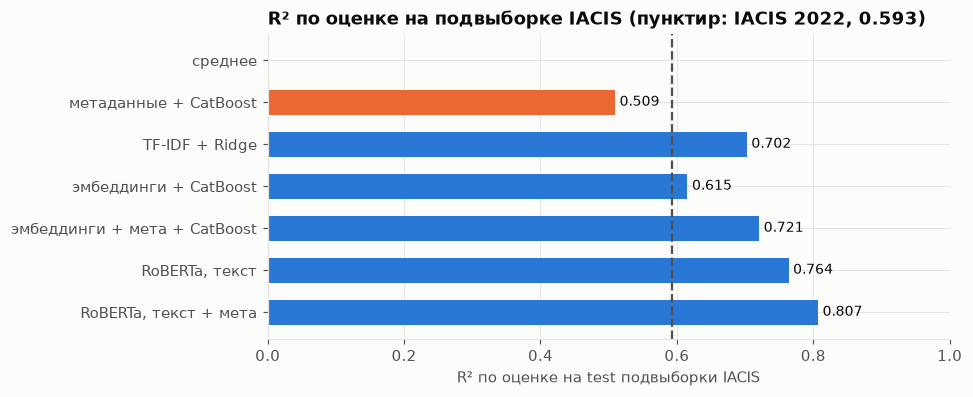

In [3]:
r2 = iacis[(POINTS_COL, "R2")]
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [MAIN if e in USES_TEXT else PALETTE[1] for e in EXPS]
bars = ax.barh(r2.index[::-1], r2.values[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axvline(0.593, color=TEXT_MUTED, lw=1.5, ls="--")
ax.set_xlim(0, 1)
ax.set_xlabel("R² по оценке на test подвыборки IACIS")
ax.set_title("R² по оценке на подвыборке IACIS (пунктир: IACIS 2022, 0.593)")
save(fig, "iacis_r2")
plt.show()

## 2. Классификация: сравнение с Journal of Wine Economics 2022

Два подхода:
- **классы из регрессии:** непрерывный прогноз оценки переводится в класс по границам посередине
  между баллами (89.5 для 2 классов; 84.5, 89.5, 94.5 для 4 классов);
- **отдельные классификаторы RoBERTa** только на тексте, как в статье (ниже).
Классы несбалансированы, поэтому для ориентира считаем и accuracy мажоритарного класса, и macro-F1.

In [4]:
y_points = test[POINTS_COL]
for k in (2, 4):
    share = points_to_class(y_points, k).value_counts(normalize=True).sort_index()
    print(f"{k} класса, доли на test, %:", (share * 100).round(1).tolist())

2 класса, доли на test, %: [62.2, 37.8]
4 класса, доли на test, %: [10.3, 51.9, 35.8, 2.0]


In [5]:
rows = {}
for k in (2, 4):
    y_true = points_to_class(y_points, k).values
    for e in EXPS:
        if e == "mean":
            # для классификации вместо среднего берём мажоритарный класс
            name, y_pred = "majority", np.full(len(y_true), np.bincount(y_true).argmax())
        else:
            name, y_pred = e, score_to_class(load_predictions(e, POINTS_COL)["y_pred"], k)
        m = classification_metrics(y_true, y_pred)
        log_metrics(name, f"class{k}", m)
        rows[("мажоритарный класс" if e == "mean" else NAMES[e], f"{k} класса")] = m
clf = pd.DataFrame(rows).T.unstack(1).swaplevel(0, 1, axis=1).sort_index(axis=1)
clf = clf.loc[["мажоритарный класс"] + [NAMES[e] for e in EXPS[1:]]]
clf.round(3)

2 класса          4 класса         
                             Accuracy F1_macro Accuracy F1_macro
мажоритарный класс              0.622    0.384    0.519    0.171
метаданные + CatBoost           0.777    0.756    0.664    0.407
TF-IDF + Ridge                  0.842    0.829    0.749    0.606
эмбеддинги + CatBoost           0.813    0.796    0.716    0.538
эмбеддинги + мета + CatBoost    0.847    0.835    0.758    0.605
RoBERTa, текст                  0.863    0.853    0.784    0.696
RoBERTa, текст + мета           0.877    0.869    0.808    0.737

### Отдельные классификаторы RoBERTa

Как в JWE 2022: RoBERTa-base только на тексте, отдельная модель для 2 и для 4 классов, cross-entropy.
Гиперпараметры те же, что у регрессии в ноутбуке 04 (3 эпохи, lr 2e-5, batch 32, bf16), лучший чекпойнт выбирается по accuracy на val.
Обучение ~15 мин на модель на RTX 5060; если предсказания на test уже сохранены, модель не переобучается.

In [6]:
import torch
from transformers.utils import logging as hf_logging
from src.config import ROOT, TEXT_COL
from src.metrics import save_predictions
from src.transformer import TrainConfig, train_classifier, predict_proba

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
train_full, val_full, _ = load_splits()
CLS_NAME = "RoBERTa-классификатор, текст"

for k in (2, 4):
    run = f"roberta_cls{k}"
    path = ROOT / "results" / "predictions" / f"{run}__class{k}.parquet"
    if not path.exists():
        print(f"--- {run}")
        model, tok, hist = train_classifier(
            train_full[TEXT_COL], points_to_class(train_full[POINTS_COL], k).values,
            val_full[TEXT_COL], points_to_class(val_full[POINTS_COL], k).values,
            k, TrainConfig(), run_name=run,
        )
        hist.to_csv(ROOT / "results" / f"{run}_history.csv", index=False)
        y_pred = predict_proba(model, tok, test[TEXT_COL], TrainConfig()).argmax(1)
        save_predictions(run, f"class{k}", test.index, points_to_class(y_points, k).values, y_pred)
        del model
        torch.cuda.empty_cache()
    p = pd.read_parquet(path)
    m = classification_metrics(p["y_true"], p["y_pred"])
    log_metrics(run, f"class{k}", m)
    for metric, v in m.items():
        clf.loc[CLS_NAME, (f"{k} класса", metric)] = v
clf.round(3)

--- roberta_cls2


epoch 0.25  train 0.4528  val_loss 0.3520  val_acc 0.8369  *  1.2 мин


epoch 0.50  train 0.3710  val_loss 0.3611  val_acc 0.8283  2.5 мин


epoch 0.75  train 0.3499  val_loss 0.3393  val_acc 0.8466  *  3.7 мин


epoch 1.00  train 0.3376  val_loss 0.3245  val_acc 0.8510  *  5.0 мин


epoch 1.25  train 0.2955  val_loss 0.3286  val_acc 0.8512  *  6.2 мин


... (17 outputs left out)

epoch 2.50  train 0.4185  val_loss 0.5262  val_acc 0.7773  12.5 мин


epoch 2.75  train 0.4197  val_loss 0.5201  val_acc 0.7794  *  13.7 мин


epoch 3.00  train 0.4074  val_loss 0.5235  val_acc 0.7799  *  14.9 мин


2 класса          4 класса         
                             Accuracy F1_macro Accuracy F1_macro
мажоритарный класс              0.622    0.384    0.519    0.171
метаданные + CatBoost           0.777    0.756    0.664    0.407
TF-IDF + Ridge                  0.842    0.829    0.749    0.606
эмбеддинги + CatBoost           0.813    0.796    0.716    0.538
эмбеддинги + мета + CatBoost    0.847    0.835    0.758    0.605
RoBERTa, текст                  0.863    0.853    0.784    0.696
RoBERTa, текст + мета           0.877    0.869    0.808    0.737
RoBERTa-классификатор, текст    0.863    0.853    0.786    0.704

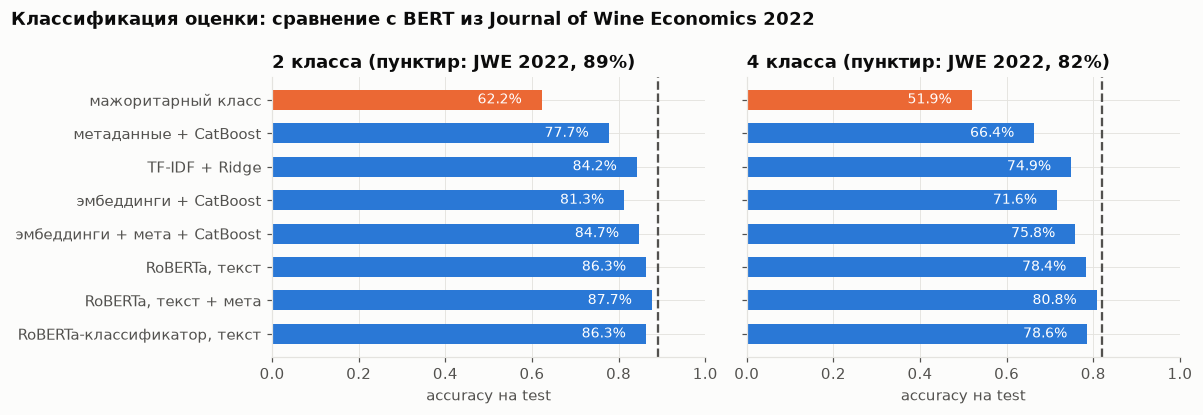

In [7]:
ref = {2: 0.89, 4: 0.82}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = clf.index
for ax, k in zip(axes, (2, 4)):
    acc = clf[(f"{k} класса", "Accuracy")]
    colors = [PALETTE[1] if l == "мажоритарный класс" else MAIN for l in labels]
    bars = ax.barh(labels[::-1], acc.values[::-1], color=colors[::-1], height=0.6)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in acc.values[::-1]], padding=-42, fontsize=9, color="white")
    ax.axvline(ref[k], color=TEXT_MUTED, lw=1.5, ls="--")
    ax.set_xlim(0, 1)
    ax.set_title(f"{k} класса (пунктир: JWE 2022, {ref[k]:.0%})")
    ax.set_xlabel("accuracy на test")
fig.suptitle("Классификация оценки: сравнение с BERT из Journal of Wine Economics 2022",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "classification_accuracy")
plt.show()

Матрицы ошибок лучшей модели только на тексте (RoBERTa), по строкам нормированы на истинный класс:

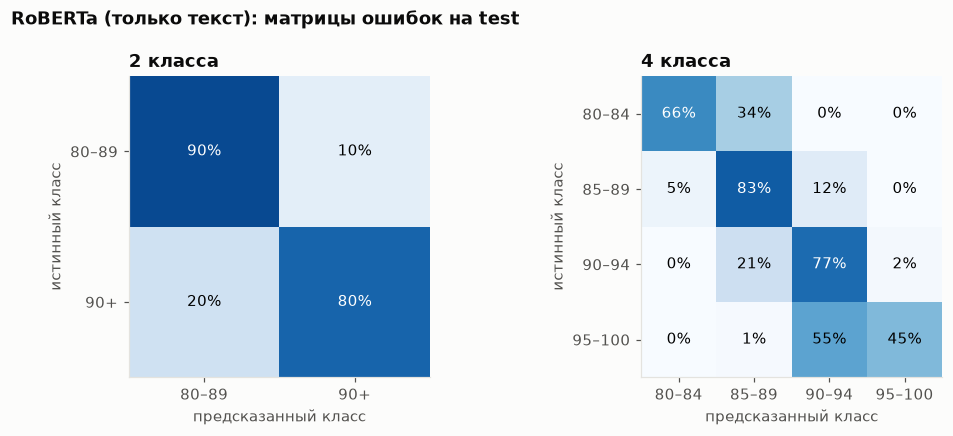

In [8]:
CLASS_NAMES = {2: ["80–89", "90+"], 4: ["80–84", "85–89", "90–94", "95–100"]}
p = load_predictions("roberta_text", POINTS_COL)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, k in zip(axes, (2, 4)):
    cm = confusion_matrix(points_to_class(y_points, k), score_to_class(p["y_pred"], k), normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > 0.6 else "black")
    ax.set_xticks(range(k), CLASS_NAMES[k])
    ax.set_yticks(range(k), CLASS_NAMES[k])
    ax.set_xlabel("предсказанный класс")
    ax.set_ylabel("истинный класс")
    ax.set_title(f"{k} класса")
fig.suptitle("RoBERTa (только текст): матрицы ошибок на test", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "classification_confusion")
plt.show()

Матрицы ошибок отдельных классификаторов RoBERTa:

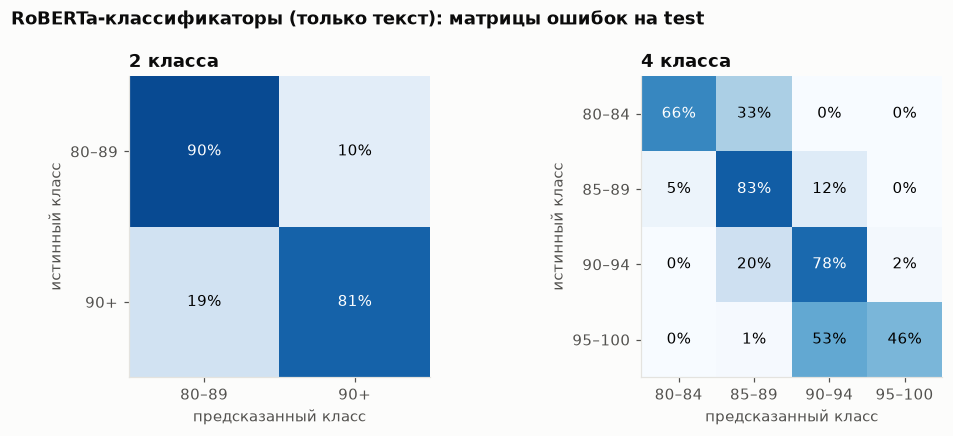

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.6]})
for ax, k in zip(axes, (2, 4)):
    p = pd.read_parquet(ROOT / "results" / "predictions" / f"roberta_cls{k}__class{k}.parquet")
    cm = confusion_matrix(p["y_true"], p["y_pred"], normalize="true", labels=range(k))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    for i in range(k):
        for j in range(k):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if cm[i, j] > 0.6 else "black")
    ax.set_xticks(range(k), CLASS_NAMES[k])
    ax.set_yticks(range(k), CLASS_NAMES[k])
    ax.set_xlabel("предсказанный класс")
    ax.set_ylabel("истинный класс")
    ax.set_title(f"{k} класса")
fig.suptitle("RoBERTa-классификаторы (только текст): матрицы ошибок на test", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "classification_confusion_cls")
plt.show()

## Выводы по экспериментам 7–8

**Эксперимент 7, IACIS 2022 (R² = 0.593).** На test подвыборки (6 612 отзывов) RoBERTa только на тексте даёт R² 0.764,
с метаданными в тексте 0.807. Результат статьи превосходит даже TF-IDF + Ridge (0.702), а чистые метаданные до него не дотягивают (0.509).
Оговорки: списки стран, сортов и дегустаторов восстановлены приближённо (самые частые категории), а наши модели обучены на полном train,
то есть на большем объёме данных, чем у авторов.

**Эксперимент 8, Journal of Wine Economics 2022 (BERT: 89% и 82%).** Accuracy на test:

| | 2 класса | 4 класса |
|---|---|---|
| мажоритарный класс | 62.2% | 51.9% |
| TF-IDF + Ridge (классы из регрессии) | 84.2% | 74.9% |
| RoBERTa, текст (классы из регрессии) | 86.3% | 78.4% |
| RoBERTa-классификатор, текст | 86.3% | 78.6% |
| RoBERTa, текст + метаданные (классы из регрессии) | 87.7% | 80.8% |
| JWE 2022, BERT | 89% | 82% |

- **Отдельный классификатор не лучше регрессии.** Accuracy совпадает (86.3%) или выше на 0.2 п.п. (78.6%), матрицы ошибок почти одинаковые.
  Значит, отставание от статьи не связано с тем, что классы получены из регрессии: на наших данных RoBERTa-base по тексту упирается в ~86% и ~79%.
- До статьи не хватает 2.7 п.п. (2 класса) и 3.4 п.п. (4 класса) по тексту, с метаданными в тексте 1.3 / 1.2 п.п.
- **Где ошибается модель:** ~19–20% вин 90+ получают класс 80–89; из класса 95–100 (2% test) верно распознаётся меньше половины,
  остальные уходят в 90–94. Через класс модель почти не ошибается: путаются только соседние классы, у границы 89/90 тексты почти неотличимы.
- **Возможная причина разрыва — протокол.** Мы удалили дубликаты описаний: в исходных данных у 15.4% строк есть точная копия текста.
  Если в статье дубликаты оставлены, около 8% отзывов test имеют идентичный отзыв в train, и accuracy вырастает примерно на 1 п.п.
  Протокол статьи (очистка, разбиение, фильтр по цене) мы проверить не можем, поэтому это гипотеза, а не объяснение всего разрыва.

## 3. SHAP: что RoBERTa видит в тексте

Вклады считаются `shap.PartitionExplainer` по токенам: части текста маскируются, и смотрится, как меняется прогноз.
Объясняется прогноз в исходной шкале: баллы для `points` и log(цены) для `log_price`. Сумма вкладов всех токенов плюс базовое
значение (прогноз на полностью замаскированном тексте) равна прогнозу модели.

Берём 400 случайных отзывов из test (~1 с на отзыв на GPU, значения кэшируются в `data/processed/shap/`).
BPE-токены склеиваются в слова, вклад слова равен сумме вкладов его токенов.

Проверка ниже сравнивает «базовое значение + сумма вкладов» с прогнозами, сохранёнными в ноутбуке 04. Небольшие расхождения ожидаемы:
прогноз в bf16 немного зависит от состава батча, а маскер SHAP в редких случаях искажает не-ASCII символы при склейке токенов
(например, «über» превращается в «üüber»).

In [10]:
from src.config import SEED, TEXT_COL
from src.transformer import Scaler, text_with_meta
from src.interpret import explain, word_attributions, top_words, segment_attributions, SEGMENTS

train, _, _ = load_splits()
TARGETS = [POINTS_COL, LOG_PRICE_COL]
scaler = Scaler(train[TARGETS].values.astype(np.float32))  # та же стандартизация, что при обучении
sample = test.sample(400, random_state=SEED)

sv_text = explain("roberta_text", sample[TEXT_COL], scaler, TARGETS)
sv_meta = explain("roberta_meta", text_with_meta(sample), scaler, TARGETS)

# проверка аддитивности: базовое значение + сумма вкладов = сохранённый прогноз на test
for name, sv in {"roberta_text": sv_text, "roberta_meta": sv_meta}.items():
    for j, t in enumerate(TARGETS):
        recon = np.array([v[:, j].sum() for v in sv.values]) + sv.base_values[:, j]
        saved = load_predictions(name, t).loc[sample.index, "y_pred"].values
        d = np.abs(recon - saved)
        print(f"{name:13s} {t:9s} расхождение с сохранённым прогнозом: медиана {np.median(d):.3f}, "
              f"макс. {d.max():.3f}, > 0.1: {(d > 0.1).sum()} из {len(d)}")

roberta_text  points    расхождение с сохранённым прогнозом: медиана 0.006, макс. 0.363, > 0.1: 5 из 400
roberta_text  log_price расхождение с сохранённым прогнозом: медиана 0.003, макс. 0.086, > 0.1: 0 из 400
roberta_meta  points    расхождение с сохранённым прогнозом: медиана 0.012, макс. 0.387, > 0.1: 11 из 400
roberta_meta  log_price расхождение с сохранённым прогнозом: медиана 0.003, макс. 0.227, > 0.1: 2 из 400


### Слова, которые сильнее всего сдвигают прогноз (RoBERTa, только текст)

Средний вклад слова по всем его вхождениям, среди слов, встретившихся хотя бы в 10 из 400 отзывов.

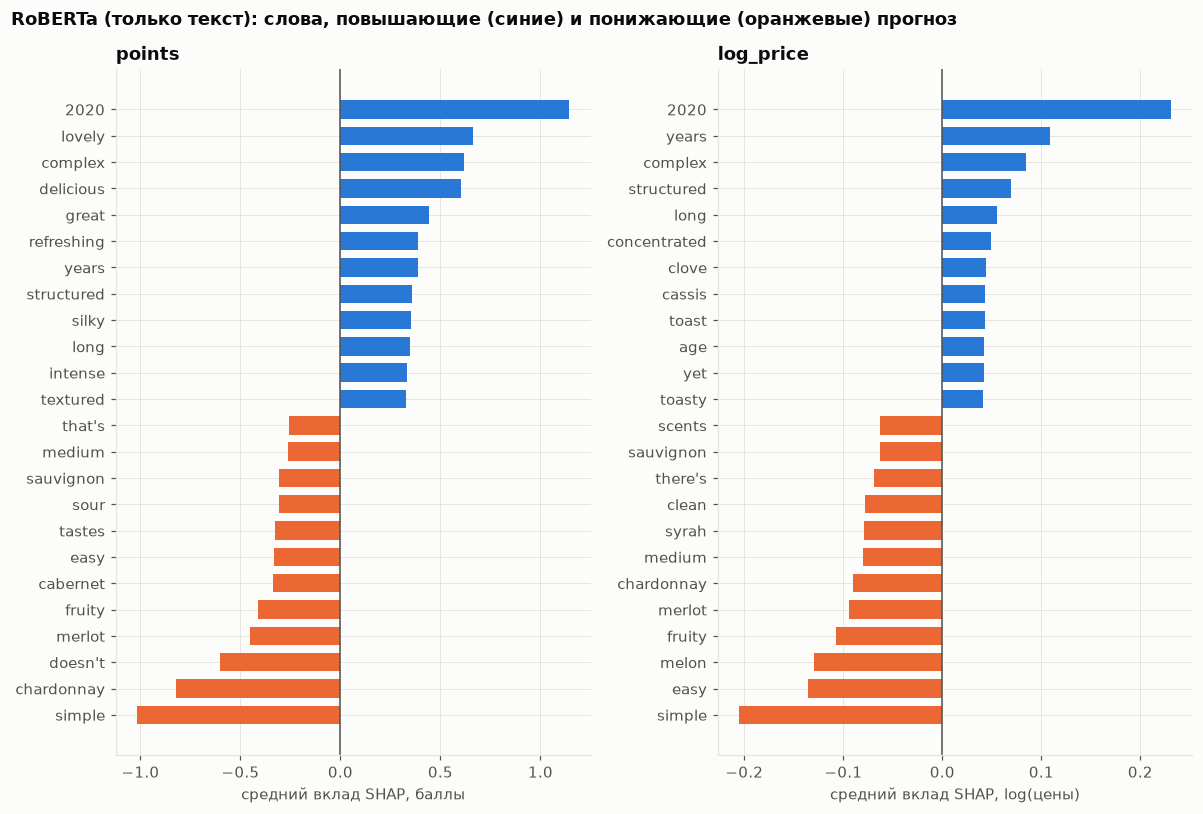

In [11]:
UNITS = {POINTS_COL: "баллы", LOG_PRICE_COL: "log(цены)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 7.5))
tops = {}
for ax, (j, t) in zip(axes, enumerate(TARGETS)):
    tw = top_words(word_attributions(sv_text, j), min_docs=10, n=12)["mean_shap"]
    tops[t] = tw
    tw = tw.sort_values()
    ax.barh(tw.index, tw.values, color=[MAIN if v > 0 else PALETTE[1] for v in tw.values], height=0.7)
    ax.axvline(0, color=TEXT_MUTED, lw=1)
    ax.set_title(t)
    ax.set_xlabel(f"средний вклад SHAP, {UNITS[t]}")
fig.suptitle("RoBERTa (только текст): слова, повышающие (синие) и понижающие (оранжевые) прогноз",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "shap_top_words")
plt.show()

Два примера: отзыв с самым высоким и с самым низким прогнозом оценки среди 400. Красным подсвечены токены, повышающие прогноз, синим понижающие.

In [12]:
import shap
pred_points = np.array([v[:, 0].sum() for v in sv_text.values]) + sv_text.base_values[:, 0]
for i in (pred_points.argmax(), pred_points.argmin()):
    row = sample.iloc[i]
    print(f"истинная оценка {row[POINTS_COL]}, прогноз {pred_points[i]:.1f}")
    shap.plots.text(sv_text[i, :, 0])

истинная оценка 95, прогноз 96.1


истинная оценка 82, прогноз 81.2


## 4. SHAP: вклад метаданных в тексте (RoBERTa, текст + метаданные)

Вклады токенов суммируются по полям входа `Country: ... Province: ... Region: ... Variety: ... Winery: ... Taster: ... Description: ...`.
Средний модуль вклада показывает, насколько сильно поле в среднем сдвигает прогноз в любую сторону.

средний |SHAP|             доля          
                    points log_price points log_price
Country              0.231     0.104    4.8      11.3
Province             0.242     0.100    5.0      10.8
Region               0.367     0.121    7.6      13.1
Variety              0.283     0.118    5.8      12.8
Winery               0.313     0.104    6.4      11.3
Taster               0.429     0.058    8.8       6.3
Description          2.987     0.317   61.6      34.4

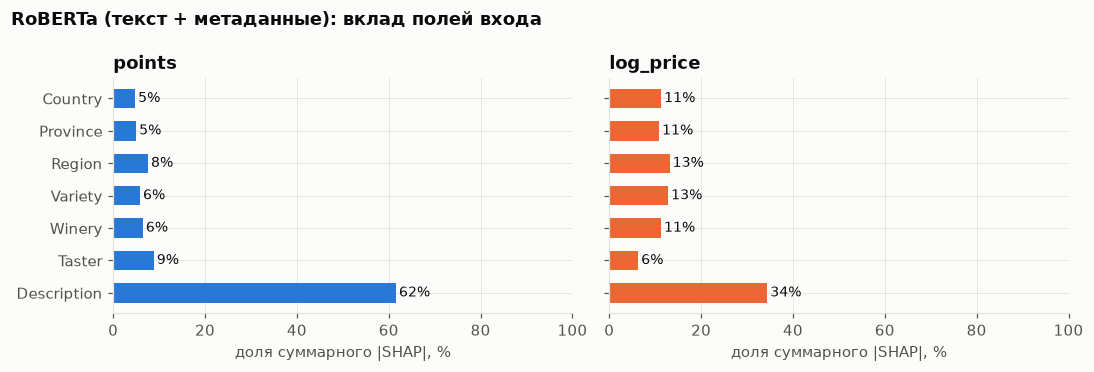

In [13]:
seg = {t: segment_attributions(sv_meta, j) for j, t in enumerate(TARGETS)}
seg_abs = pd.DataFrame({t: seg[t].abs().mean() for t in TARGETS}).loc[SEGMENTS]
seg_share = seg_abs / seg_abs.sum()
display(pd.concat({"средний |SHAP|": seg_abs.round(3), "доля": (seg_share * 100).round(1)}, axis=1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
order = SEGMENTS[::-1]
for ax, t, c in zip(axes, TARGETS, (MAIN, PALETTE[1])):
    bars = ax.barh(order, seg_share.loc[order, t] * 100, color=c, height=0.6)
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=9)
    ax.set_xlim(0, 100)
    ax.set_title(t)
    ax.set_xlabel("доля суммарного |SHAP|, %")
fig.suptitle("RoBERTa (текст + метаданные): вклад полей входа", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "shap_segments")
plt.show()

## 5. Анализ ошибок

Используем предсказания на всём test (11 157 отзывов) двух RoBERTa. Остаток = прогноз − истинное значение.

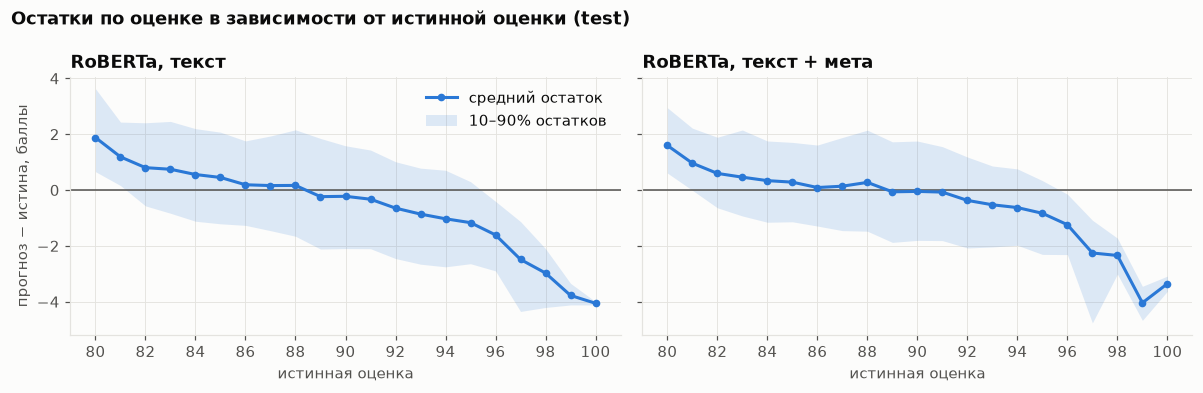

In [14]:
err = test[[POINTS_COL, LOG_PRICE_COL, "taster_name", "country", TEXT_COL]].copy()
err["taster_name"] = err["taster_name"].fillna("не указан")
err["n_words"] = err[TEXT_COL].str.split().str.len()
for e in ("roberta_text", "roberta_meta"):
    for t in TARGETS:
        err[f"{e}__{t}"] = load_predictions(e, t)["y_pred"].values - err[t].values

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
pts = np.arange(80, 101)
for ax, e in zip(axes, ("roberta_text", "roberta_meta")):
    g = err.groupby(POINTS_COL)[f"{e}__{POINTS_COL}"]
    ax.axhline(0, color=TEXT_MUTED, lw=1)
    ax.plot(g.mean().index, g.mean().values, color=MAIN, marker="o", ms=4, label="средний остаток")
    q = g.quantile([0.1, 0.9]).unstack()
    ax.fill_between(q.index, q[0.1], q[0.9], color=MAIN, alpha=0.15, lw=0, label="10–90% остатков")
    ax.set_title(NAMES[e])
    ax.set_xlabel("истинная оценка")
    ax.set_xticks(pts[::2])
axes[0].set_ylabel("прогноз − истина, баллы")
axes[0].legend(loc="upper right")
fig.suptitle("Остатки по оценке в зависимости от истинной оценки (test)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "errors_by_points")
plt.show()

Ошибка по дегустаторам и по длине отзыва (MAE по оценке):

In [15]:
def mae_by(col, min_n=100):
    g = err.groupby(col)
    out = pd.DataFrame({
        "отзывов": g.size(),
        "MAE текст": g[f"roberta_text__{POINTS_COL}"].apply(lambda r: r.abs().mean()),
        "MAE текст + мета": g[f"roberta_meta__{POINTS_COL}"].apply(lambda r: r.abs().mean()),
        "смещение текст": g[f"roberta_text__{POINTS_COL}"].mean(),
    })
    out = out[out["отзывов"] >= min_n]
    out["выигрыш от мета"] = out["MAE текст"] - out["MAE текст + мета"]
    return out.round(2)

display(mae_by("taster_name").sort_values("MAE текст", ascending=False))
err["длина, слов"] = pd.cut(err["n_words"], [0, 25, 35, 45, 60, 200])
display(mae_by("длина, слов", min_n=1))

,отзывов,MAE текст,MAE текст + мета,смещение текст,выигрыш от мета
taster_name,,,,,
Susan Kostrzewa,105,1.56,1.19,0.74,0.37
Virginie Boone,758,1.30,1.16,0.05,0.14
Joe Czerwinski,456,1.26,1.17,-0.06,0.09
Matt Kettmann,606,1.25,1.22,-0.09,0.03
Roger Voss,1878,1.25,1.13,-0.03,0.12
Jim Gordon,357,1.22,1.13,-0.28,0.09
Anna Lee C. Iijima,400,1.19,0.99,0.21,0.21
Lauren Buzzeo,163,1.19,0.90,0.66,0.29
Paul Gregutt,898,1.18,1.04,-0.27,0.15


,отзывов,MAE текст,MAE текст + мета,смещение текст,выигрыш от мета
"длина, слов",,,,,
"(0, 25]",777,1.09,0.97,-0.16,0.12
"(25, 35]",2950,1.13,1.01,-0.14,0.13
"(35, 45]",4038,1.18,1.06,-0.09,0.12
"(45, 60]",2895,1.17,1.08,0.04,0.09
"(60, 200]",497,1.18,1.09,0.24,0.08


Самые большие ошибки модели только на тексте:

In [16]:
pd.set_option("display.max_colwidth", 300)
col = f"roberta_text__{POINTS_COL}"
worst = err.reindex(err[col].abs().sort_values(ascending=False).index).head(8)
worst.assign(прогноз=(worst[POINTS_COL] + worst[col]).round(1))[
    [POINTS_COL, "прогноз", "taster_name", "country", TEXT_COL]]

,points,прогноз,taster_name,country,description
2351,94,85.8,Joe Czerwinski,Australia,"A perplexing wine to evaluate, the 2010 RunRig (97% Shiraz and 3% Viognier) evolves rapidly once poured, going from slightly stewed and overoaked to a wine that shows considerable class within 20 minutes or so. Aromas and flavors of brown sugar, mocha and roasted meat give way to raspberry compo..."
41543,96,88.9,Jeff Jenssen,Hungary,"Straw colored with gold reflections, this delightful sweet wine has aromas of dried pear, fresh apricot and yellow peach. Flavors of fresh Bartlett pear, acacia honey and tinned apricots unfold on the palate. The finish is sweet, with just the right amount of acidity."
46346,94,87.3,Roger Voss,France,"Fermentation in wood has given this wine a rich spicy character that contrasts with the honey and lemon fruitiness and the mineral texture. Aromatic and perfumed with summer blossoms, it is ready to drink."
1478,97,90.4,не указан,Italy,"The 2008 Ornellaia delivers concentrated aromas of forest fruit, raspberry and black cherry. There are beautiful elements of soft spice and chocolate at the back and the wine ends with soft, plush tannins and smooth, berry-rich flavors."
24501,92,85.8,Jim Gordon,US,"Something different and almost irrestible, this red dessert wine is high in alcohol but still comes off as a table wine in flavor, but with obvious, tasty sweetness. Beyond that the flavors and slight grip of tannins seem like those of a big red wine."
43663,82,88.2,Anna Lee C. Iijima,US,"Exuberantly perfumed with notes of honey, tangerine and orange flowers, this rich, sweet sparkler is effusive on the palate as well with flavors of ripe melon, fruit cocktail and peach gummy candy."
89584,82,88.1,Michael Schachner,Argentina,"A gold color indicates maturation, while loud, tropical fruit aromas fold in lychee, citrus blossom and sweat. The palate is electric due to citric acidity, while flavors of orange, tangerine, lemon-lime and grapefruit finish with a chalky feel."
61490,94,87.9,Roger Voss,France,"This is a wine for aging. The tannins are dense, very dry with a feel of extraction. It takes a while for the black currant fruit to show through, with acidity and freshness dominant. The wine is still settling, and time will bring the fruit into line with the tannins."


## Выводы по эксперименту 9

**Что RoBERTa считает признаком хорошего вина** (только текст, 400 отзывов из test):
- *Повышают оценку:* оценочная лексика (*lovely, complex, delicious, great*), структура и длительность (*structured, long, intense, textured, silky*)
  и потенциал выдержки (*years*, а также годы в окнах потребления вроде «drink through 2020»: самый сильный сигнал, +1.1 балла в среднем).
- *Понижают:* *simple* (−1.0), отрицания (*doesn't*), *easy, fruity, sour, medium*. Модель понимает, что «простое, лёгкое, фруктовое» вино получает меньше баллов.
- *Названия сортов* (*chardonnay, merlot, cabernet, sauvignon*) в среднем понижают прогноз: модель выучила, что массовые сорта
  чаще получают средние оценки и стоят дешевле. Это априорная информация о сорте, извлечённая из текста.
- *Цена* опирается на те же сигналы выдержки и сложности (*years, age, structured, concentrated*) и на «дубовые» дескрипторы (*toast, toasty, clove, cassis*),
  которые характерны для дорогих красных вин с выдержкой в бочке; *simple, easy, melon, fruity* указывают на дешёвые вина.
  Это согласуется с коэффициентами TF-IDF + Ridge из ноутбука 02, но RoBERTa учитывает контекст (например, отрицание *doesn't*).

**Вклад метаданных** (RoBERTa с метаданными в тексте, доля суммарного |SHAP|):

| | points | log_price |
|---|---|---|
| Description | 62% | 34% |
| все метаданные | 38% | 66% |
| самое важное поле | Taster 9% | Region 13% |

Для оценки главный источник информации — текст, из метаданных больше всего весит дегустатор (личная шкала).
Для цены две трети вклада приходятся на происхождение: регион, сорт, страна, провинция и винодельня. Это объясняет, почему метаданные
так сильно улучшили прогноз цены (R² 0.56 → 0.71) и слабо оценки (0.77 → 0.81).

**Анализ ошибок.**
- *Регрессия к среднему.* Модель завышает низкие оценки (+1.9 балла у вин на 80) и занижает высокие (−2.5 у 97, −4 у 99–100).
  Метаданные уменьшают смещение в середине шкалы, но для 97+ почти не помогают: таких вин в train мало, а текст выдающегося вина
  мало отличается от текста очень хорошего. Это та же причина, по которой класс 95–100 плохо распознаётся в эксперименте 8.
- *Дегустаторы.* MAE от 0.88 (Kerin O’Keefe) до 1.56 (Susan Kostrzewa). У дегустаторов с собственной шкалой модель на тексте даёт
  систематическое смещение (+0.74 у Kostrzewa, +0.66 у Lauren Buzzeo), и именно у них метаданные дают наибольший выигрыш (0.37 и 0.29 балла MAE).
- *Длина отзыва* почти не влияет на ошибку (MAE 1.09–1.18), но длинные отзывы модель немного переоценивает: длина сама коррелирует с оценкой.
- *Худшие ошибки* — десертные и сладкие вина (токайское, red dessert wine, сладкое игристое), где описание вкуса не совпадает
  с обычной шкалой, и отзывы, в которых сомелье описывает недостатки молодого вина с большим потенциалом
  (*«perplexing wine to evaluate»*, *«still settling, time will bring the fruit into line»*): модель снижает оценку за критику,
  а дегустатор ставит высокий балл за будущее вина.